In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset from a path relative to the project or notebook folder.
from pathlib import Path

DATASET_CANDIDATES = [
    Path.cwd() / "data" / "students_with_id.csv",
    Path.cwd().parent / "data" / "students_with_id.csv",
]
DATA_PATH = next((path for path in DATASET_CANDIDATES if path.is_file()), None)

if DATA_PATH is None:
    searched = "\n".join(str(path.resolve()) for path in DATASET_CANDIDATES)
    raise FileNotFoundError(
        "Could not find students_with_id.csv. Searched:\n" + searched
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns from {DATA_PATH.resolve()}")

Loaded 4,424 rows and 38 columns from D:\ML_project\data\students_with_id.csv


## Dataset loading and validation

The loader checks the project-level `data/` folder and the parent folder, so it works whether Jupyter starts in the project root or the `notbooks/` directory. Validation reports duplicates without deleting rows and stops if the audited schema, target, or data types change unexpectedly.

In [3]:
# Validate the source dataset before analysis or modeling.

EXPECTED_TARGET = "Target"
EXPECTED_CLASSES = {"Graduate", "Dropout", "Enrolled"}
EXPECTED_COLUMNS = {
    "Student_ID", "Marital status", "Application mode", "Application order",
    "Course", "Daytime/evening attendance\t", "Previous qualification",
    "Previous qualification (grade)", "Nacionality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    "Admission grade", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "Age at enrollment",
    "International", "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate", "Inflation rate", "GDP", EXPECTED_TARGET,
}

missing_columns = EXPECTED_COLUMNS - set(df.columns)
unexpected_columns = set(df.columns) - EXPECTED_COLUMNS
print("Missing expected columns:", sorted(missing_columns))
print("Unexpected columns:", sorted(unexpected_columns))

if EXPECTED_TARGET not in df.columns:
    raise ValueError(f"Required target column {EXPECTED_TARGET!r} is missing.")
if missing_columns or unexpected_columns:
    raise ValueError("Dataset columns do not match the audited schema; review before modeling.")

missing_values = df.isna().sum()
print("Missing values by column:")
print(missing_values[missing_values > 0] if missing_values.any() else "None")

exact_duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows (reported, not removed): {exact_duplicate_count}")
if "Student_ID" in df.columns:
    duplicate_id_count = int(df["Student_ID"].duplicated().sum())
    print(f"Duplicate Student_ID values: {duplicate_id_count}")

non_numeric_features = df.drop(columns=[EXPECTED_TARGET]).select_dtypes(exclude="number").columns.tolist()
print("Non-numeric feature columns:", non_numeric_features)

observed_classes = set(df[EXPECTED_TARGET].dropna().unique())
print("Target classes:", sorted(observed_classes))
print("Target distribution:")
print(df[EXPECTED_TARGET].value_counts(dropna=False))

if df[EXPECTED_TARGET].isna().any():
    raise ValueError("Target contains missing values; investigate before training.")
if observed_classes != EXPECTED_CLASSES:
    raise ValueError(f"Expected target classes {EXPECTED_CLASSES}, found {observed_classes}.")
if non_numeric_features:
    raise TypeError(f"Feature columns must be numeric in this dataset: {non_numeric_features}")


Missing expected columns: []
Unexpected columns: []
Missing values by column:
None
Exact duplicate rows (reported, not removed): 0
Duplicate Student_ID values: 0
Non-numeric feature columns: []
Target classes: ['Dropout', 'Enrolled', 'Graduate']
Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


## Prediction timing and feature eligibility

This experiment estimates the eventual `Target` after first-semester information is available. The model uses admission/background fields and first-semester records. `Student_ID` is reserved for record lookup, `Target` is the label, and all second-semester curricular-unit fields are excluded because they are not yet available at this prediction point. The CSV contains historical labels, so evaluation is retrospective on held-out records; an operational app would need current student records containing the eligible features and would not show a known target as a prediction.

In [4]:
# Keep lookup identity and future-semester information out of model inputs.
TARGET_COLUMN = "Target"
ID_COLUMN = "Student_ID"
SECOND_SEMESTER_COLUMNS = [
    column for column in df.columns
    if column.startswith("Curricular units 2nd sem (")
]
EXCLUDED_MODEL_COLUMNS = [TARGET_COLUMN, ID_COLUMN, *SECOND_SEMESTER_COLUMNS]

missing_required = {TARGET_COLUMN, ID_COLUMN} - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")
if not SECOND_SEMESTER_COLUMNS:
    raise ValueError("No second-semester columns found; review the audited schema.")

X = df.drop(columns=EXCLUDED_MODEL_COLUMNS)
y = df[TARGET_COLUMN].copy()

assert ID_COLUMN not in X.columns
assert TARGET_COLUMN not in X.columns
assert not set(SECOND_SEMESTER_COLUMNS).intersection(X.columns)
print("Prediction time: after first-semester results are available")
print("Excluded ID and target columns:", [ID_COLUMN, TARGET_COLUMN])
print("Excluded second-semester columns:", SECOND_SEMESTER_COLUMNS)
print("Model feature count:", X.shape[1])
print("Selected model features in order:", list(X.columns))
print("Target labels:", sorted(y.unique()))


Prediction time: after first-semester results are available
Excluded ID and target columns: ['Student_ID', 'Target']
Excluded second-semester columns: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Model feature count: 30
Target labels: ['Dropout', 'Enrolled', 'Graduate']


## Exploratory data analysis

The following charts describe the historical dataset. Semester-two plots are descriptive only; second-semester fields are excluded from the after-first-semester model.

In [5]:
df.head()

,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1001,1,17,5,171,1,1,122.0,1,19,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1002,1,15,1,9254,1,1,160.0,1,1,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1003,1,1,5,9070,1,1,122.0,1,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1004,1,17,2,9773,1,1,122.0,1,38,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,1005,2,39,1,8014,0,1,100.0,1,37,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [6]:
df.shape

(4424, 38)

In [7]:
df.columns.tolist()

['Student_ID',
 'Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance\t',
 'Previous qualification',
 'Previous qualification (grade)',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate'

In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Student_ID                                      4424 non-null   int64  
 1   Marital status                                  4424 non-null   int64  
 2   Application mode                                4424 non-null   int64  
 3   Application order                               4424 non-null   int64  
 4   Course                                          4424 non-null   int64  
 5   Daytime/evening attendance	                     4424 non-null   int64  
 6   Previous qualification                          4424 non-null   int64  
 7   Previous qualification (grade)                  4424 non-null   float64
 8   Nacionality                                     4424 non-null   int64  
 9   Mother's qualification                   

In [9]:
df.isnull().sum()

Student_ID                                        0
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship 

In [10]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

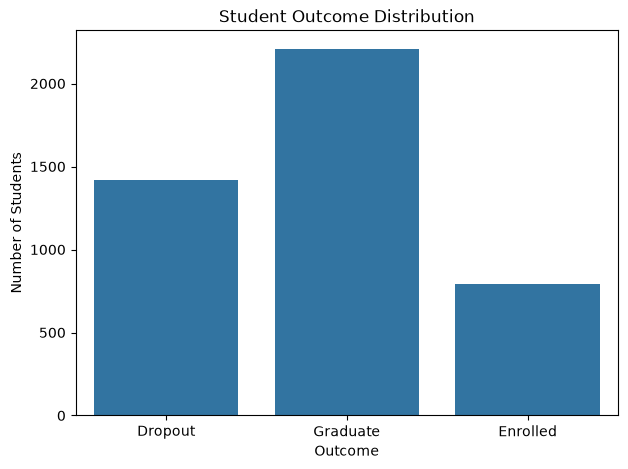

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Target")

plt.title("Student Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")

plt.show()

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Student_ID,4424.0,3212.500000,1277.243125,1001.00,2106.75,3212.500000,4318.250000,5424.000000
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000


In [13]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

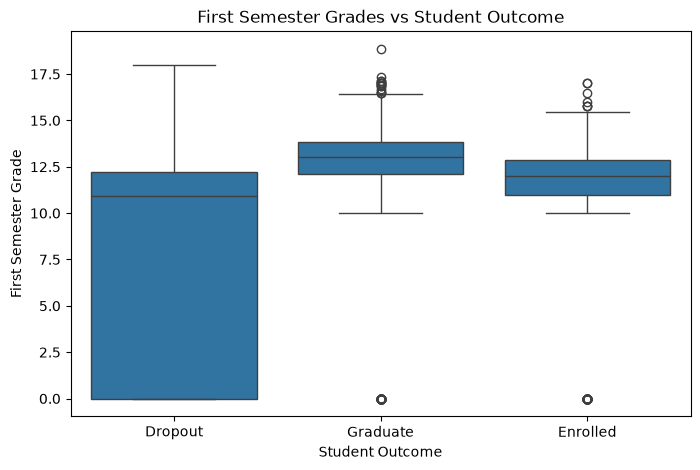

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)"
)

plt.title("First Semester Grades vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("First Semester Grade")

plt.show()

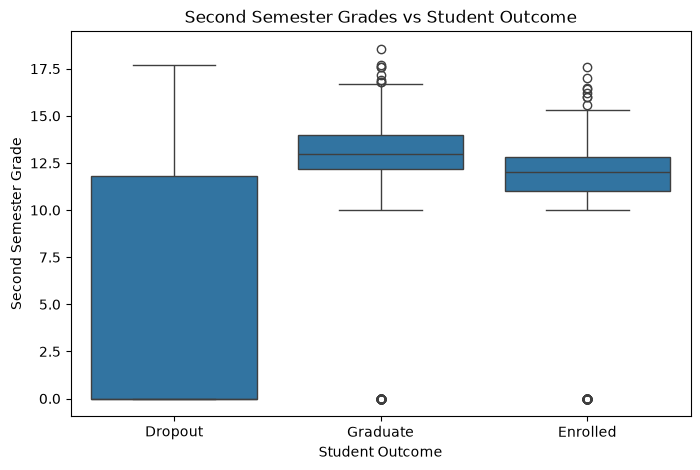

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (grade)"
)

plt.title("Second Semester Grades vs Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Second Semester Grade")

plt.show()

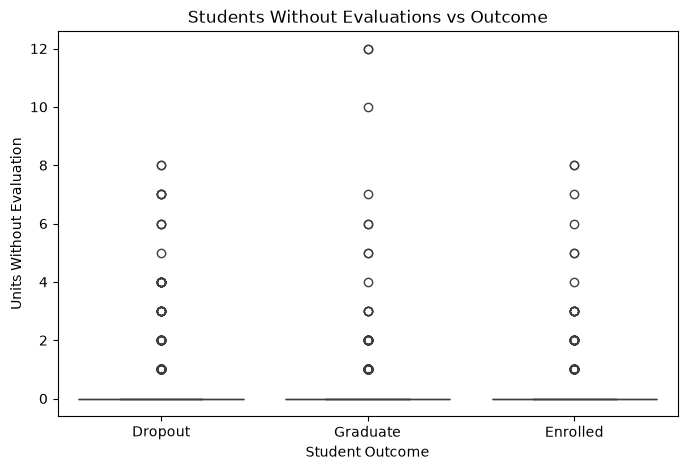

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (without evaluations)"
)

plt.title("Students Without Evaluations vs Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Units Without Evaluation")

plt.show()

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


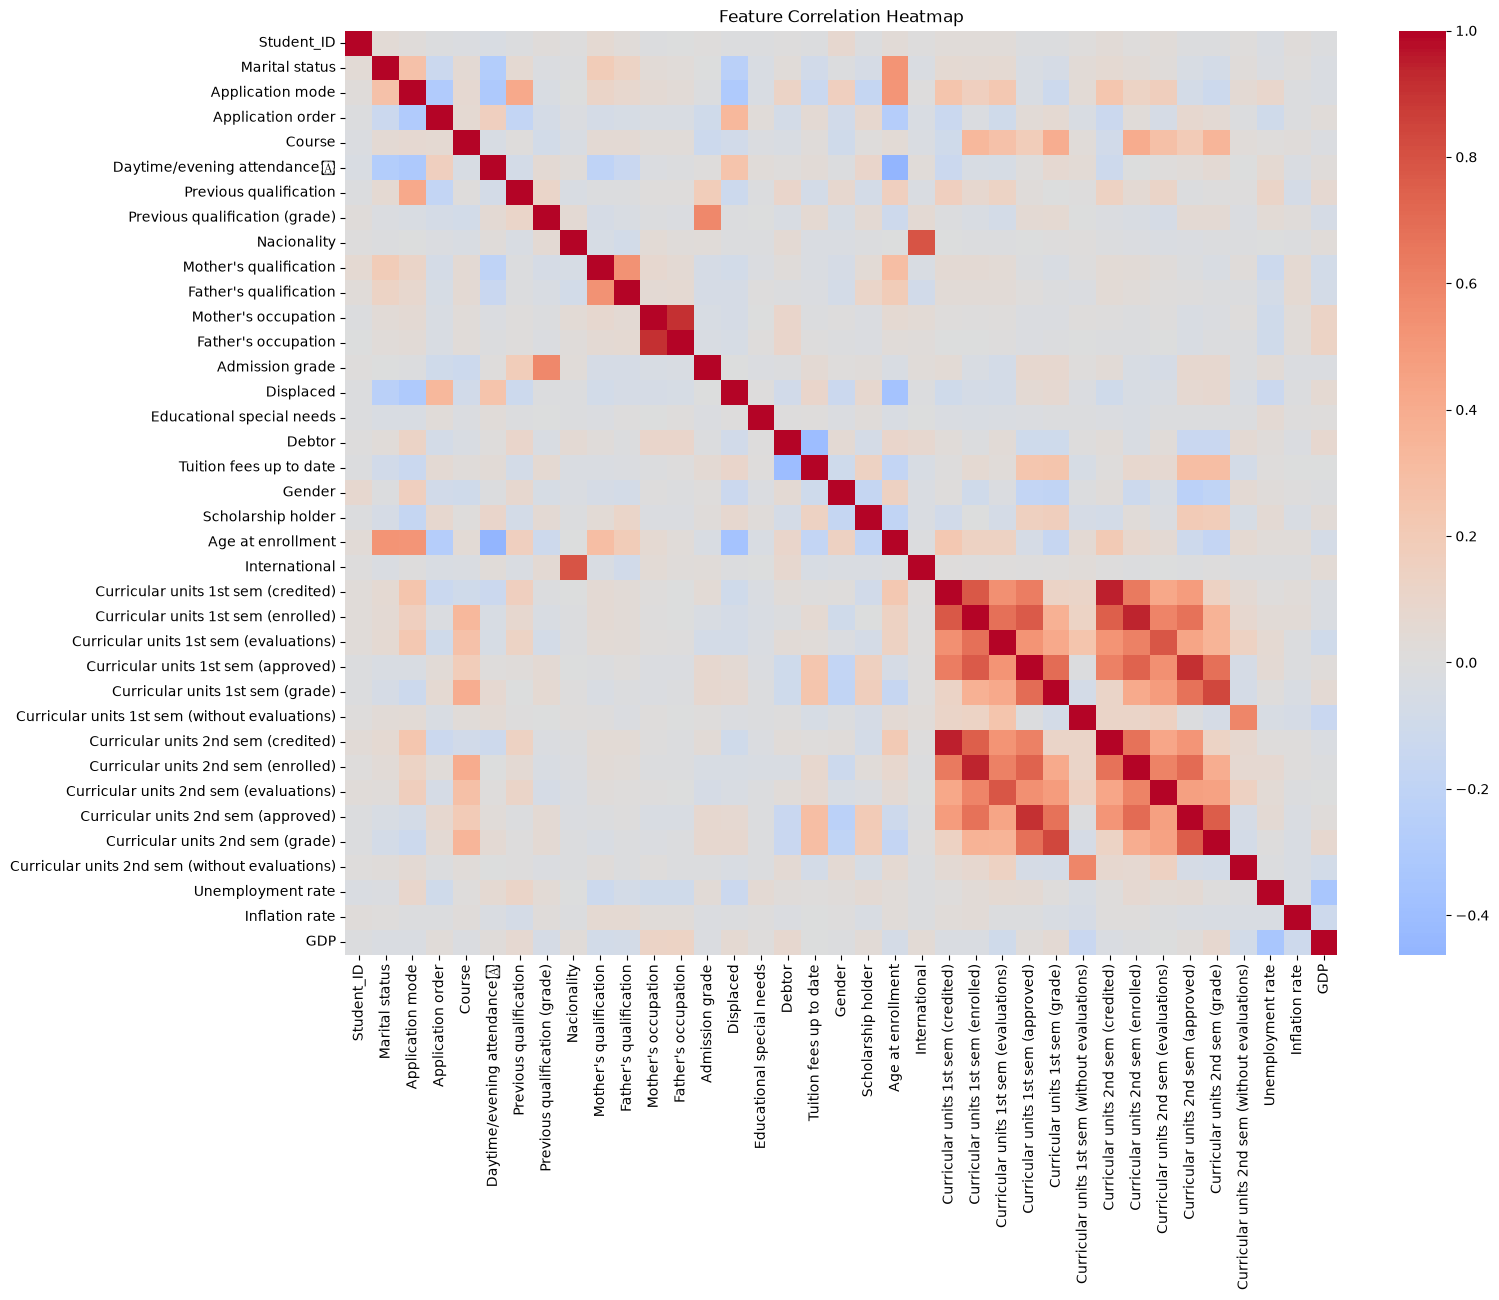

In [17]:
plt.figure(figsize=(16,12))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

## STEP 4 — Reproducible split and leakage-safe preprocessing

We create one stratified 80/20 split and keep the held-out test rows out of all preprocessing fits and hyperparameter searches. Features are all numeric in storage, but many are coded categories. Categorical values are one-hot encoded; Logistic Regression also scales numeric values. Tree models keep numeric values at their original scale. Each transform is inside a scikit-learn pipeline so cross-validation refits it only on each training fold.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report, confusion_matrix)
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20


In [ ]:
# Verify that the selected feature list remains the single source of truth.
assert X.shape[1] == 30, f"Expected 30 features, found {X.shape[1]}"
assert ID_COLUMN not in X.columns and TARGET_COLUMN not in X.columns
assert not set(SECOND_SEMESTER_COLUMNS).intersection(X.columns)
assert df[ID_COLUMN].is_unique, "Student_ID must uniquely identify each row for lookup."

train_indices, test_indices = train_test_split(
    df.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
X_train, X_test = X.loc[train_indices].copy(), X.loc[test_indices].copy()
y_train, y_test = y.loc[train_indices].copy(), y.loc[test_indices].copy()

assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Train/test row overlap:", len(set(X_train.index).intersection(X_test.index)))
print("Full-dataset class distribution:")
print(y.value_counts().reindex(sorted(EXPECTED_CLASSES)))
print("Training class distribution:")
print(y_train.value_counts().reindex(sorted(EXPECTED_CLASSES)))
print("Training proportions:")
print(y_train.value_counts(normalize=True).reindex(sorted(EXPECTED_CLASSES)).round(3))


### Preprocessing design

The binary indicators and coded nominal fields are treated as categories. Application order, grades, age, semester-one unit counts, and economic indicators remain numeric. No records are resampled: the class imbalance is moderate, so we will inspect macro F1 and per-class recall before deciding whether any balancing is justified. The existing Random Forest class-weight setting is retained and evaluated against the unweighted Logistic Regression and XGBoost baselines.

In [ ]:
CATEGORICAL_FEATURES = [
    "Marital status", "Application mode", "Course", "Daytime/evening attendance\t",
    "Previous qualification", "Nacionality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    "Displaced", "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International",
]
CATEGORICAL_FEATURES = [column for column in CATEGORICAL_FEATURES if column in X.columns]
NUMERIC_FEATURES = [column for column in X.columns if column not in CATEGORICAL_FEATURES]

assert set(CATEGORICAL_FEATURES).isdisjoint(NUMERIC_FEATURES)
assert set(CATEGORICAL_FEATURES + NUMERIC_FEATURES) == set(X.columns)
assert all(pd.api.types.is_numeric_dtype(X[column]) for column in X.columns)


def make_preprocessor(scale_numeric=False):
    numeric_transform = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_transform, NUMERIC_FEATURES),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )

print(f"Categorical columns: {len(CATEGORICAL_FEATURES)}")
print(f"Numeric columns: {len(NUMERIC_FEATURES)}")


### Baseline model pipelines

All three existing model families are retained. Logistic Regression scales only its numeric fields. Random Forest and XGBoost receive one-hot encoded categorical fields and unscaled numeric fields. The target labels are encoded only for XGBoost because that estimator requires numeric class codes; the mapping is retained to convert predictions back to the original names.

In [ ]:
label_encoder = LabelEncoder().fit(sorted(EXPECTED_CLASSES))
y_train_encoded = label_encoder.transform(y_train)

logistic_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=True)),
    ("classifier", LogisticRegression(max_iter=2000, solver="newton-cholesky", random_state=RANDOM_STATE)),
])
random_forest_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1
    )),
])
xgboost_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=False)),
    ("classifier", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=1,
    )),
])

logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)
xgboost_pipeline.fit(X_train, y_train_encoded)
print("All three baseline pipelines fitted on training data only.")


### Training-only hyperparameter searches

The existing Random Forest and XGBoost parameter grids are retained. The grids now search pipeline estimator parameters, use stratified five-fold cross-validation with a fixed seed, and optimize macro F1 to give each outcome class equal weight. `GridSearchCV.fit` receives training rows only; the test set is not passed to either search.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
}
rf_grid = GridSearchCV(
    estimator=Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=False)),
        ("classifier", RandomForestClassifier(
            random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1
        )),
    ]),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)
rf_grid.fit(X_train, y_train)
print("Random Forest best training-CV macro F1:", round(rf_grid.best_score_, 4))
print("Random Forest best parameters:", rf_grid.best_params_)


In [ ]:
xgb_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 5, 7],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
}
xgb_grid = GridSearchCV(
    estimator=Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=False)),
        ("classifier", XGBClassifier(
            random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=1
        )),
    ]),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)
xgb_grid.fit(X_train, y_train_encoded)
print("XGBoost best training-CV macro F1:", round(xgb_grid.best_score_, 4))
print("XGBoost best parameters:", xgb_grid.best_params_)


## STEP 5 — Training-only class-imbalance experiment

The prior STEP 4 run evaluated multiple candidates on the held-out test set. For this step, the test set is deliberately not used again. All comparisons below use the training partition only and one new seeded, stratified five-fold split. The new seed keeps these folds separate from STEP 4 hyperparameter selection folds. Every candidate uses the same folds; preprocessing remains inside its pipeline and is refit within each fold.

We compare a majority-class `DummyClassifier`, the existing unweighted Logistic Regression and XGBoost baselines, the existing class-weighted Random Forest baseline, and paired weighted/unweighted alternatives. XGBoost weights are computed separately from each fold’s training labels. The tuned tree candidates are included as reference models, but their STEP 4 CV scores are not reused for this comparison.

In [ ]:
# All performance estimates in this section are out-of-fold predictions on X_train only.
IMBALANCE_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

full_class_counts = y.value_counts().reindex(sorted(EXPECTED_CLASSES))
training_class_counts = y_train.value_counts().reindex(sorted(EXPECTED_CLASSES))
print("Full dataset class counts:")
print(full_class_counts)
print("Training-set class counts:")
print(training_class_counts)

# The folds are shared by every candidate; only training-partition rows enter this loop.
imbalance_candidates = {
    "Majority dummy": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=False)),
            ("classifier", DummyClassifier(strategy="most_frequent")),
        ]),
        "encode_target": False, "balanced_sample_weight": False,
    },
    "Logistic Regression unweighted": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=True)),
            ("classifier", LogisticRegression(
                max_iter=2000, solver="newton-cholesky", random_state=RANDOM_STATE,
                class_weight=None,
            )),
        ]),
        "encode_target": False, "balanced_sample_weight": False,
    },
    "Logistic Regression balanced": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=True)),
            ("classifier", LogisticRegression(
                max_iter=2000, solver="newton-cholesky", random_state=RANDOM_STATE,
                class_weight="balanced",
            )),
        ]),
        "encode_target": False, "balanced_sample_weight": False,
    },
    "Random Forest unweighted": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=False)),
            ("classifier", RandomForestClassifier(
                n_estimators=300, random_state=RANDOM_STATE, class_weight=None, n_jobs=1,
            )),
        ]),
        "encode_target": False, "balanced_sample_weight": False,
    },
    "Random Forest balanced": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=False)),
            ("classifier", RandomForestClassifier(
                n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=1,
            )),
        ]),
        "encode_target": False, "balanced_sample_weight": False,
    },
    "Random Forest tuned reference": {
        "pipeline": rf_grid.best_estimator_,
        "encode_target": False, "balanced_sample_weight": False,
    },
    "XGBoost unweighted": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=False)),
            ("classifier", XGBClassifier(
                n_estimators=300, learning_rate=0.05, max_depth=5,
                random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=1,
            )),
        ]),
        "encode_target": True, "balanced_sample_weight": False,
    },
    "XGBoost balanced sample weights": {
        "pipeline": Pipeline([
            ("preprocess", make_preprocessor(scale_numeric=False)),
            ("classifier", XGBClassifier(
                n_estimators=300, learning_rate=0.05, max_depth=5,
                random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=1,
            )),
        ]),
        "encode_target": True, "balanced_sample_weight": True,
    },
    "XGBoost tuned reference": {
        "pipeline": xgb_grid.best_estimator_,
        "encode_target": True, "balanced_sample_weight": False,
    },
}

fold_metric_rows = []
oof_predictions = {
    name: pd.Series(index=y_train.index, dtype=object)
    for name in imbalance_candidates
}

for candidate_name, candidate in imbalance_candidates.items():
    print(f"Evaluating {candidate_name} using training folds only...", flush=True)
    for fold_number, (fit_positions, valid_positions) in enumerate(
        IMBALANCE_CV.split(X_train, y_train), start=1
    ):
        fold_model = clone(candidate["pipeline"])
        X_fold_train = X_train.iloc[fit_positions]
        X_fold_valid = X_train.iloc[valid_positions]
        y_fold_train = y_train.iloc[fit_positions]
        y_fold_valid = y_train.iloc[valid_positions]

        if candidate["encode_target"]:
            y_fold_fit = label_encoder.transform(y_fold_train)
            fit_parameters = {}
            if candidate["balanced_sample_weight"]:
                fit_parameters["classifier__sample_weight"] = compute_sample_weight(
                    class_weight="balanced", y=y_fold_fit
                )
            fold_model.fit(X_fold_train, y_fold_fit, **fit_parameters)
            pred_codes = fold_model.predict(X_fold_valid).astype(int)
            fold_predictions = label_encoder.inverse_transform(pred_codes)
        else:
            fold_model.fit(X_fold_train, y_fold_train)
            fold_predictions = fold_model.predict(X_fold_valid)

        oof_predictions[candidate_name].iloc[valid_positions] = fold_predictions
        fold_metric_rows.append({
            "Model": candidate_name,
            "Fold": fold_number,
            "Macro F1": f1_score(y_fold_valid, fold_predictions, average="macro", zero_division=0),
            "Balanced accuracy": balanced_accuracy_score(y_fold_valid, fold_predictions),
            "Dropout recall": recall_score(y_fold_valid, fold_predictions, labels=["Dropout"], average="macro", zero_division=0),
            "Enrolled recall": recall_score(y_fold_valid, fold_predictions, labels=["Enrolled"], average="macro", zero_division=0),
            "Graduate recall": recall_score(y_fold_valid, fold_predictions, labels=["Graduate"], average="macro", zero_division=0),
        })

fold_metrics = pd.DataFrame(fold_metric_rows)
summary_rows = []
for candidate_name, predictions in oof_predictions.items():
    assert predictions.notna().all(), f"Missing out-of-fold predictions for {candidate_name}"
    candidate_folds = fold_metrics[fold_metrics["Model"] == candidate_name]
    summary_rows.append({
        "Model": candidate_name,
        "CV macro F1 mean": candidate_folds["Macro F1"].mean(),
        "CV macro F1 std": candidate_folds["Macro F1"].std(ddof=0),
        "CV balanced accuracy mean": candidate_folds["Balanced accuracy"].mean(),
        "CV Dropout recall mean": candidate_folds["Dropout recall"].mean(),
        "CV Enrolled recall mean": candidate_folds["Enrolled recall"].mean(),
        "CV Graduate recall mean": candidate_folds["Graduate recall"].mean(),
        "OOF macro F1": f1_score(y_train, predictions, average="macro", zero_division=0),
        "OOF balanced accuracy": balanced_accuracy_score(y_train, predictions),
    })

imbalance_summary = pd.DataFrame(summary_rows).sort_values(
    "CV macro F1 mean", ascending=False
).reset_index(drop=True)
imbalance_summary.round(4)


### Out-of-fold class reports and confusion matrices

These reports pool each training row’s prediction from the fold in which it was held out. Support therefore reflects the training partition only. The matrix order is Dropout, Enrolled, Graduate. No held-out test record is scored in this experiment.

In [ ]:
CV_LABELS = ["Dropout", "Enrolled", "Graduate"]
for candidate_name, predictions in oof_predictions.items():
    print(f"\n{candidate_name} — training out-of-fold report")
    print(classification_report(
        y_train, predictions, labels=CV_LABELS, target_names=CV_LABELS, zero_division=0
    ))
    print("Confusion matrix (actual rows, predicted columns):")
    print(confusion_matrix(y_train, predictions, labels=CV_LABELS))

fig, axes = plt.subplots(3, 3, figsize=(16, 15))
for ax, (candidate_name, predictions) in zip(axes.flat, oof_predictions.items()):
    matrix = confusion_matrix(y_train, predictions, labels=CV_LABELS)
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=CV_LABELS, yticklabels=CV_LABELS, ax=ax,
    )
    ax.set_title(candidate_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


### Measured effect of class weighting

Each difference below is weighted minus its unweighted counterpart, averaged across the same five folds. Positive Enrolled recall means more Enrolled students were identified in validation folds; it may come with trade-offs in other classes. This is a training-only comparison and does not choose a final production model.

In [ ]:
mean_cv = fold_metrics.groupby("Model").mean(numeric_only=True)
weight_pairs = [
    ("Logistic Regression", "Logistic Regression unweighted", "Logistic Regression balanced"),
    ("Random Forest", "Random Forest unweighted", "Random Forest balanced"),
    ("XGBoost", "XGBoost unweighted", "XGBoost balanced sample weights"),
]
weight_effect_rows = []
for family, unweighted_name, weighted_name in weight_pairs:
    weight_effect_rows.append({
        "Model family": family,
        "Change in macro F1": mean_cv.loc[weighted_name, "Macro F1"] - mean_cv.loc[unweighted_name, "Macro F1"],
        "Change in balanced accuracy": mean_cv.loc[weighted_name, "Balanced accuracy"] - mean_cv.loc[unweighted_name, "Balanced accuracy"],
        "Change in Enrolled recall": mean_cv.loc[weighted_name, "Enrolled recall"] - mean_cv.loc[unweighted_name, "Enrolled recall"],
    })
weight_effects = pd.DataFrame(weight_effect_rows)
weight_effects.round(4)


## Final candidate selection using training-only cross-validation

Selection rule: identify the candidate with the highest mean five-fold macro F1. Form a one-standard-error set using the top candidate’s fold-to-fold standard error (`sample standard deviation / sqrt(5)`). Among candidates within that range, choose the one with the highest mean Enrolled recall; use balanced accuracy and model simplicity as tie-breakers. This keeps macro F1 primary while recognizing the project’s weak Enrolled recall. This rule uses only the training partition; the held-out test scores are not available to this step.

In [ ]:
# Training-only selection; the held-out test partition is not referenced here.
cv_top_row = imbalance_summary.iloc[0]
cv_top_name = cv_top_row["Model"]
cv_top_fold_scores = fold_metrics.loc[
    fold_metrics["Model"] == cv_top_name, "Macro F1"
]
cv_top_standard_error = cv_top_fold_scores.std(ddof=1) / np.sqrt(len(cv_top_fold_scores))
selection_floor = cv_top_row["CV macro F1 mean"] - cv_top_standard_error
one_se_candidates = imbalance_summary[
    imbalance_summary["CV macro F1 mean"] >= selection_floor
].copy()

# Within one SE of the best macro F1, prioritize Enrolled recall, then balanced accuracy,
# then macro F1. Logistic Regression is simpler than either tree ensemble.
selected_row = one_se_candidates.sort_values(
    ["CV Enrolled recall mean", "CV balanced accuracy mean", "CV macro F1 mean"],
    ascending=False,
).iloc[0]
SELECTED_CANDIDATE = selected_row["Model"]
assert SELECTED_CANDIDATE == "Logistic Regression balanced"

print("Highest mean CV macro F1 candidate:", cv_top_name)
print(f"One-standard-error allowance: {cv_top_standard_error:.4f}")
print(f"Macro F1 eligibility floor: {selection_floor:.4f}")
print("Candidates within the one-standard-error set:")
print(one_se_candidates[["Model", "CV macro F1 mean", "CV Enrolled recall mean", "CV balanced accuracy mean"]].to_string(index=False))
print("Selected using the documented training-only rule:", SELECTED_CANDIDATE)


## One-time held-out test evaluation

After locking the candidate above, refit its complete preprocessing-and-estimator pipeline on all training rows. Evaluate it once on the existing held-out test partition and do not revise the candidate based on these results.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

selected_pipeline_template = imbalance_candidates[SELECTED_CANDIDATE]["pipeline"]
final_pipeline = clone(selected_pipeline_template)
final_pipeline.fit(X_train, y_train)

selected_features = X.columns.tolist()
assert len(selected_features) == 30
assert list(final_pipeline.feature_names_in_) == selected_features
assert ID_COLUMN not in selected_features and TARGET_COLUMN not in selected_features
assert not set(SECOND_SEMESTER_COLUMNS).intersection(selected_features)

# This is the only held-out scoring call in this finalization section.
final_test_predictions = final_pipeline.predict(X_test)
final_test_metrics = {
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Precision (macro)": precision_score(y_test, final_test_predictions, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, final_test_predictions, average="macro", zero_division=0),
    "F1 (macro)": f1_score(y_test, final_test_predictions, average="macro", zero_division=0),
    "Balanced accuracy": balanced_accuracy_score(y_test, final_test_predictions),
    "Precision (weighted)": precision_score(y_test, final_test_predictions, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, final_test_predictions, average="weighted", zero_division=0),
    "F1 (weighted)": f1_score(y_test, final_test_predictions, average="weighted", zero_division=0),
}
print("Selected model:", SELECTED_CANDIDATE)
print(pd.Series(final_test_metrics).round(4).to_string())
print("Per-class test report:")
print(classification_report(
    y_test,
    final_test_predictions,
    labels=["Dropout", "Enrolled", "Graduate"],
    target_names=["Dropout", "Enrolled", "Graduate"],
    zero_division=0,
))
print("Test confusion matrix (rows=actual, columns=predicted; Dropout, Enrolled, Graduate):")
final_test_confusion = confusion_matrix(
    y_test, final_test_predictions, labels=["Dropout", "Enrolled", "Graduate"]
)
print(final_test_confusion)


## Save and reload the selected complete pipeline

The artifact contains the fitted ColumnTransformer and Logistic Regression estimator in one scikit-learn pipeline. The pipeline stores its expected input feature names and class labels. The smoke test uses one eligible held-out feature row and prints only the predicted class; it does not expose the recorded target.

In [ ]:
import joblib

PROJECT_ROOT = DATA_PATH.resolve().parent.parent
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_PATH = MODEL_DIR / "student_outcome_pipeline.joblib"

joblib.dump(final_pipeline, ARTIFACT_PATH)
reloaded_pipeline = joblib.load(ARTIFACT_PATH)
assert list(reloaded_pipeline.feature_names_in_) == selected_features
assert set(reloaded_pipeline.named_steps["classifier"].classes_) == EXPECTED_CLASSES

smoke_record = X_test.iloc[[0]].loc[:, selected_features]
reloaded_prediction = reloaded_pipeline.predict(smoke_record)
assert len(reloaded_prediction) == 1
assert reloaded_prediction[0] in EXPECTED_CLASSES
print("Saved and reloaded pipeline:", ARTIFACT_PATH.resolve())
print("Expected input feature count:", len(reloaded_pipeline.feature_names_in_))
print("Classes:", list(reloaded_pipeline.named_steps["classifier"].classes_))
print("Reloaded pipeline smoke-test prediction:", reloaded_prediction[0])


In [ ]:
def top_pipeline_importance(fitted_pipeline, top_n=15):
    classifier = fitted_pipeline.named_steps["classifier"]
    feature_names = fitted_pipeline.named_steps["preprocess"].get_feature_names_out()
    importance = pd.Series(classifier.feature_importances_, index=feature_names)
    return importance.sort_values(ascending=False).head(top_n)

rf_importance = top_pipeline_importance(rf_grid.best_estimator_)
xgb_importance = top_pipeline_importance(xgb_grid.best_estimator_)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
rf_importance.sort_values().plot(kind="barh", ax=axes[0], title="Tuned Random Forest: top transformed features")
xgb_importance.sort_values().plot(kind="barh", ax=axes[1], title="Tuned XGBoost: top transformed features")
axes[0].set_xlabel("Feature importance")
axes[1].set_xlabel("Feature importance")
plt.tight_layout()
plt.show()


## Exploratory XGBoost SHAP (not the selected model)

SHAP is applied to the fitted XGBoost estimator after the pipeline transforms a small training sample. The class-specific plots handle SHAP versions that return multiclass values as either a list or a three-dimensional array. This section is optional: a SHAP failure is reported without interrupting training, evaluation, or the saved notebook outputs. No model artifact is saved during STEP 4.

This preserves the prior XGBoost explanation analysis. The selected Logistic Regression model is not explained by these plots.

In [ ]:
try:
    import shap

    shap_pipeline = xgb_grid.best_estimator_
    shap_sample = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)
    shap_preprocessor = shap_pipeline.named_steps["preprocess"]
    shap_matrix = shap_preprocessor.transform(shap_sample)
    if hasattr(shap_matrix, "toarray"):
        shap_matrix = shap_matrix.toarray()
    transformed_names = shap_preprocessor.get_feature_names_out()
    explainer = shap.TreeExplainer(shap_pipeline.named_steps["classifier"])
    shap_output = explainer.shap_values(shap_matrix)
    if isinstance(shap_output, list):
        class_shap_values = shap_output
    elif getattr(shap_output, "ndim", 0) == 3:
        class_shap_values = [shap_output[:, :, i] for i in range(shap_output.shape[2])]
    else:
        raise ValueError(f"Unexpected multiclass SHAP output shape: {getattr(shap_output, 'shape', None)}")

    for class_index, class_name in enumerate(label_encoder.classes_):
        print(f"SHAP feature impact for class: {class_name}")
        shap.summary_plot(
            class_shap_values[class_index], shap_matrix,
            feature_names=transformed_names, show=True,
        )
except Exception as shap_error:
    print(f"Optional SHAP section could not complete: {type(shap_error).__name__}: {shap_error}")


## Finalization status

The training-only one-standard-error rule selects Logistic Regression with balanced class weights. The one-time held-out evaluation and reload smoke test are in the preceding cells. No Flask code is part of this step.